In [1]:
# Persiapan lingkungan Colab (B3_histogram)
%cd /content
!git clone https://github.com/SuciOktavia02/simuteh-2330511010.git
%cd simuteh-2330511010
!mkdir -p notebook hasil
%cd notebook

/content
Cloning into 'simuteh-2330511010'...
remote: Enumerating objects: 261, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 261 (delta 4), reused 24 (delta 4), pack-reused 237 (from 2)
Receiving objects: 100% (261/261), 60.31 MiB | 30.11 MiB/s, done.
Resolving deltas: 100% (18/18), done.
/content/simuteh-2330511010
/content/simuteh-2330511010/notebook


teh_041.png normal {'rerata': 170.3, 'simpangan_baku': 40.3, 'min': 64, 'maks': 227, 'persen_gelap': 0.0, 'persen_terang': 4.3}
teh_042.png gelap {'rerata': 130.7, 'simpangan_baku': 44.1, 'min': 5, 'maks': 196, 'persen_gelap': 9.4, 'persen_terang': 0.0}
teh_043.png terang {'rerata': 215.6, 'simpangan_baku': 24.6, 'min': 139, 'maks': 252, 'persen_gelap': 0.0, 'persen_terang': 80.5}
teh_044.png kontras_rendah {'rerata': 157.6, 'simpangan_baku': 16.8, 'min': 107, 'maks': 188, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png bayangan {'rerata': 125.5, 'simpangan_baku': 55.0, 'min': 36, 'maks': 246, 'persen_gelap': 0.9, 'persen_terang': 13.3}


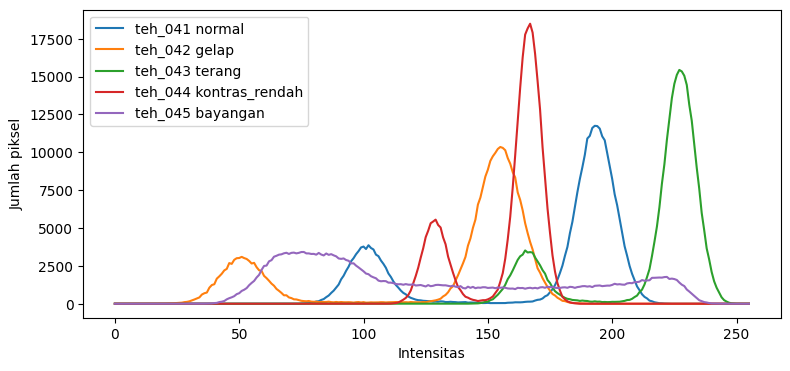

teh_021.png normal {'rerata': 172.4, 'simpangan_baku': 44.5, 'min': 76, 'maks': 216, 'persen_gelap': 0.0, 'persen_terang': 2.4}
teh_022.png gelap {'rerata': 127.0, 'simpangan_baku': 41.6, 'min': 15, 'maks': 177, 'persen_gelap': 11.9, 'persen_terang': 0.0}
teh_023.png terang {'rerata': 208.1, 'simpangan_baku': 24.2, 'min': 128, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 71.9}
teh_024.png kontras_rendah {'rerata': 156.4, 'simpangan_baku': 18.0, 'min': 112, 'maks': 185, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png bayangan {'rerata': 126.2, 'simpangan_baku': 56.9, 'min': 22, 'maks': 248, 'persen_gelap': 2.4, 'persen_terang': 12.5}


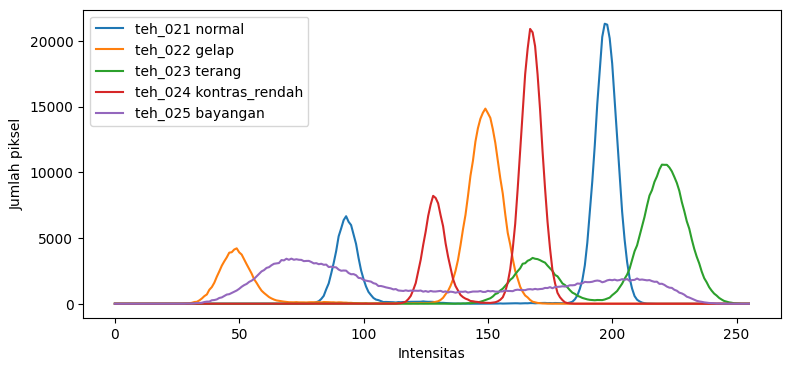

                       citra  rerata  simpangan_baku   min  maks  persen_gelap  persen_terang
            teh_041 (normal)   170.3            40.3  64.0 227.0           0.0            4.3
             teh_042 (gelap)   130.7            44.1   5.0 196.0           9.4            0.0
            teh_043 (terang)   215.6            24.6 139.0 252.0           0.0           80.5
    teh_044 (kontras_rendah)   157.6            16.8 107.0 188.0           0.0            0.0
          teh_045 (bayangan)   125.5            55.0  36.0 246.0           0.9           13.3
teh_021-025 (ringan, rerata)   158.0            37.0  70.6 216.0           2.9           17.4

                   citra  rerata  simpangan_baku  min  maks  persen_gelap  persen_terang
        teh_021 (normal)   172.4            44.5   76   216           0.0            2.4
         teh_022 (gelap)   127.0            41.6   15   177          11.9            0.0
        teh_023 (terang)   208.1            24.2  128   254           0.0 

In [2]:
# Kode 3.1 Statistik dan histogram untuk diagnosis
# (dikembangkan dari modul: ditambah kelas ringan dan pengisian Tabel 9)
import sys
sys.path.append("../src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, statistik

def gray_dari(nama):
    return cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
                        cv2.COLOR_BGR2GRAY)

kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

# ---- A. Kelas berat, lima kondisi (teh_041 sampai teh_045) ----
berat = [f"teh_{i:03d}.png" for i in range(41, 46)]
baris = []
plt.figure(figsize=(9, 4))
for nama, kd in zip(berat, kondisi):
    gray = gray_dari(nama)
    s = statistik(gray)
    print(nama, kd, s)
    baris.append({"citra": f"{nama[:-4]} ({kd})", **s})
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=f"{nama[:-4]} {kd}")
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")
plt.show()

# ---- B. Kelas ringan (teh_021 sampai teh_025) ----
ringan = [f"teh_{i:03d}.png" for i in range(21, 26)]
stat_ringan = []
plt.figure(figsize=(9, 4))
for nama, kd in zip(ringan, kondisi):
    gray = gray_dari(nama)
    s = statistik(gray)
    print(nama, kd, s)
    stat_ringan.append({"citra": f"{nama[:-4]} ({kd})", **s})
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=f"{nama[:-4]} {kd}")
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_ringan.png")
plt.show()

# ---- C. Tabel 9 Format tabel diagnosis mutu citra ----
df_ringan = pd.DataFrame(stat_ringan)
rerata_ringan = df_ringan.drop(columns="citra").mean().round(1)
baris.append({"citra": "teh_021-025 (ringan, rerata)", **rerata_ringan.to_dict()})
tabel9 = pd.DataFrame(baris)
print(tabel9.to_string(index=False))
print()
print(df_ringan.to_string(index=False))
tabel9.to_csv("../hasil/b3_tabel9.csv", index=False)
df_ringan.to_csv("../hasil/b3_tabel9_ringan_detail.csv", index=False)

In [3]:
# Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak

nama = "teh_045.png"  # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))  # abaikan 2% piksel ekstrem

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0,
                             tileGridSize=(8, 8)).apply(gray),
}

parameter = {
    "asli": "-",
    "negatif": "s = 255 - r",
    "cerah+50": "tambah 50 (saturasi)",
    "kontras": "alpha 1.5, beta -40",
    "regang": f"persentil 2-98 ({rmin:.0f}-{rmax:.0f})",
    "gamma0.5": "gamma 0.5",
    "gamma1.8": "gamma 1.8",
    "ekualisasi": "global",
    "CLAHE": "clip 2.0, tile 8x8",
}

baris = []
for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    print(f"{nm:10s} KB={kb:.2f} sigma={c.std():.1f}")
    baris.append([nm, parameter[nm], round(kb, 2), round(float(c.std()), 1)])

tabel10 = pd.DataFrame(baris, columns=["metode", "parameter", "KB",
                                       "simpangan_baku"])
print(tabel10.to_string(index=False))
tabel10.to_csv("../hasil/b3_tabel10.csv", index=False)

asli       KB=2.95 sigma=55.0
negatif    KB=2.95 sigma=55.0
cerah+50   KB=2.95 sigma=51.9
kontras    KB=2.95 sigma=74.9
regang     KB=3.04 sigma=79.9
gamma0.5   KB=2.52 sigma=38.8
gamma1.8   KB=3.81 sigma=61.1
ekualisasi KB=2.03 sigma=73.3
CLAHE      KB=2.87 sigma=48.4
    metode               parameter   KB  simpangan_baku
      asli                       - 2.95            55.0
   negatif             s = 255 - r 2.95            55.0
  cerah+50    tambah 50 (saturasi) 2.95            51.9
   kontras     alpha 1.5, beta -40 2.95            74.9
    regang persentil 2-98 (53-228) 3.04            79.9
  gamma0.5               gamma 0.5 2.52            38.8
  gamma1.8               gamma 1.8 3.81            61.1
ekualisasi                  global 2.03            73.3
     CLAHE      clip 2.0, tile 8x8 2.87            48.4


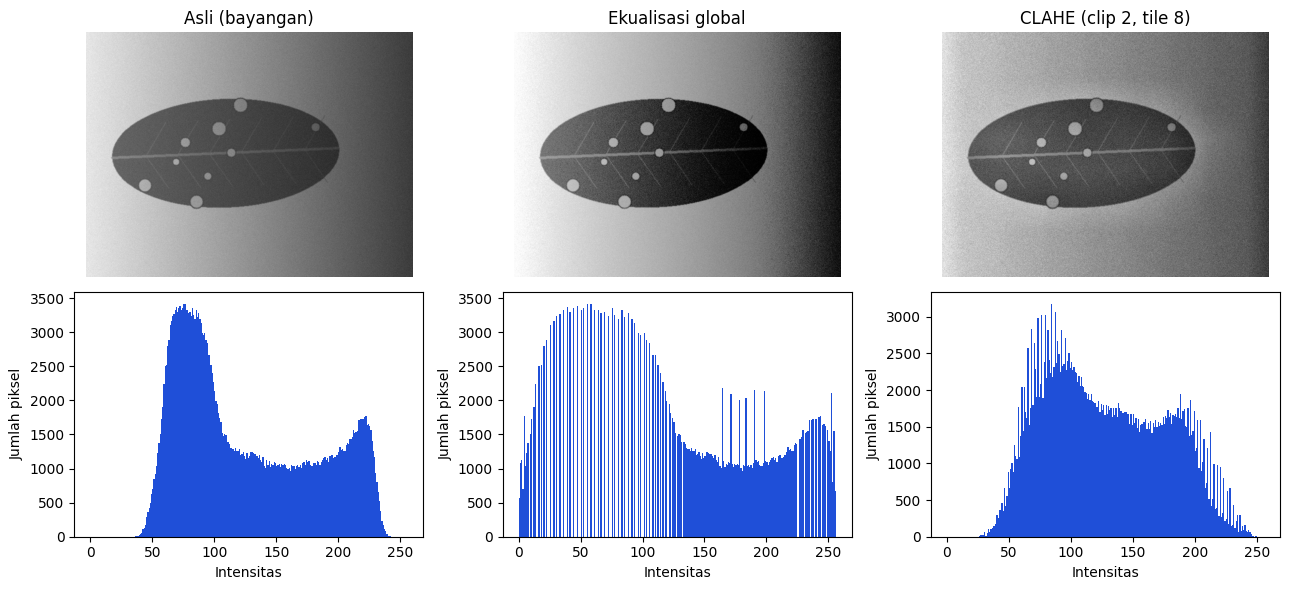

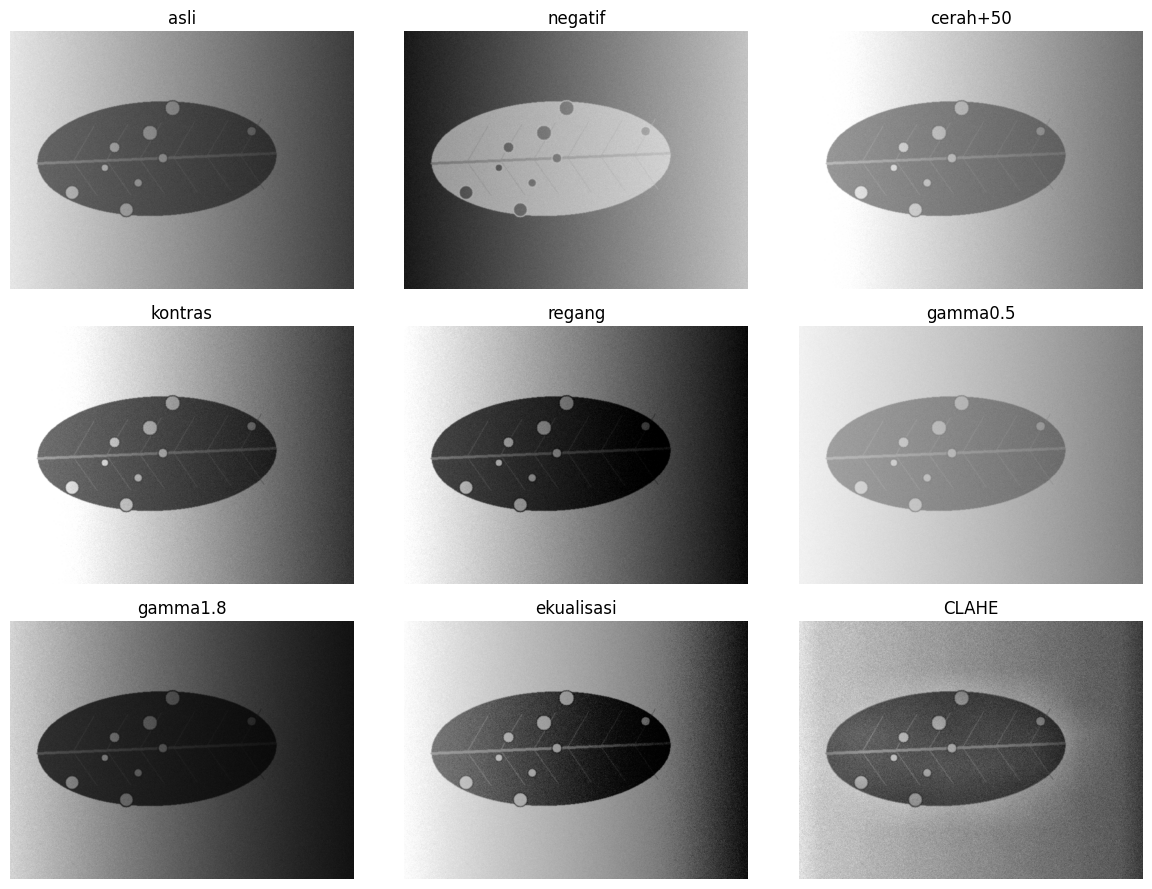

In [4]:
# Gambar 4 Perbandingan citra dan histogram sebelum serta sesudah perbaikan
pilih = ["asli", "ekualisasi", "CLAHE"]
judul = ["Asli (bayangan)", "Ekualisasi global", "CLAHE (clip 2, tile 8)"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for i, (k, jd) in enumerate(zip(pilih, judul)):
    ax[0, i].imshow(hasil[k], cmap="gray", vmin=0, vmax=255)
    ax[0, i].set_title(jd); ax[0, i].axis("off")
    ax[1, i].hist(hasil[k].ravel(), bins=256, range=(0, 256), color="#1f4fd8")
    ax[1, i].set_xlabel("Intensitas"); ax[1, i].set_ylabel("Jumlah piksel")
plt.tight_layout()
plt.savefig("../hasil/b3_gambar4_perbandingan.png", dpi=150)
plt.show()

# Panel semua metode (untuk mengisi kolom pengamatan visual Tabel 10)
fig, ax = plt.subplots(3, 3, figsize=(12, 9))
for a, (k, c) in zip(ax.ravel(), hasil.items()):
    a.imshow(c, cmap="gray", vmin=0, vmax=255)
    a.set_title(k); a.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b3_panel_metode.png", dpi=150)
plt.show()

clip=1.0 tile=4: KB=3.63
clip=1.0 tile=8: KB=3.29
clip=1.0 tile=16: KB=3.36
clip=2.0 tile=4: KB=3.41
clip=2.0 tile=8: KB=2.87
clip=2.0 tile=16: KB=2.88
clip=4.0 tile=4: KB=2.67
clip=4.0 tile=8: KB=2.28
clip=4.0 tile=16: KB=2.32


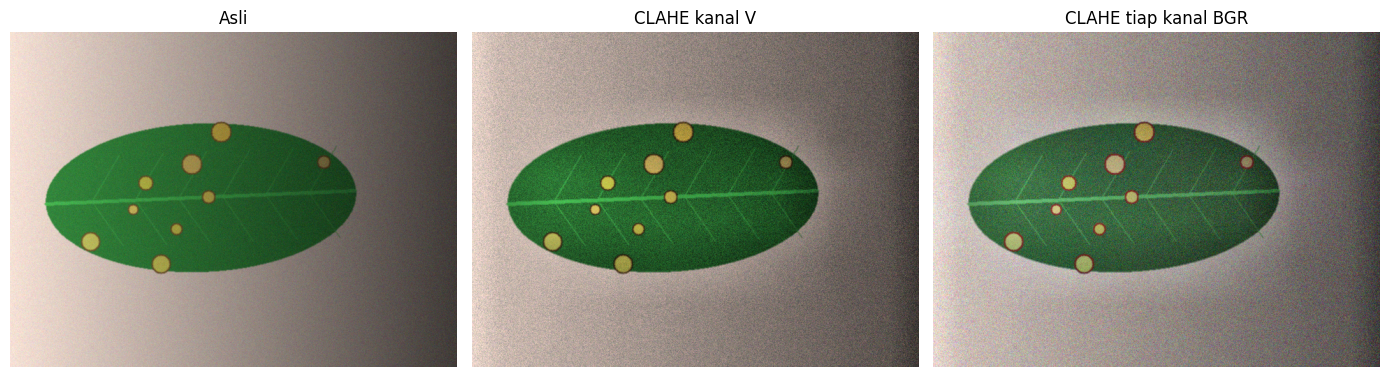

asli                   rerata Hue daun = 60.8
CLAHE kanal V          rerata Hue daun = 60.8
CLAHE tiap kanal BGR   rerata Hue daun = 62.9


In [5]:
# Kode 3.3 Eksperimen CLAHE
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

nama = "teh_045.png"  # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ---- A. Eksperimen parameter CLAHE (clipLimit x tileGridSize) ----
baris = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip,
                            tileGridSize=(tile, tile)).apply(gray)
        kb = kontras_bercak(c, md, mb)
        print(f"clip={clip} tile={tile}: KB={kb:.2f}")
        baris.append([clip, tile, round(kb, 2), round(float(c.std()), 1)])
tabel_clahe = pd.DataFrame(baris, columns=["clipLimit", "tileGridSize",
                                           "KB", "simpangan_baku"])
tabel_clahe.to_csv("../hasil/b3_clahe_parameter.csv", index=False)

# ---- B. CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR ----
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png", dpi=150)
plt.show()

# ---- C. Bukti tambahan untuk P3.4: rerata Hue pada area daun ----
def rerata_hue(bgr):
    h = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float)
    return h[md > 0].mean()

for nm, im in [("asli", img), ("CLAHE kanal V", via_v),
               ("CLAHE tiap kanal BGR", via_bgr)]:
    print(f"{nm:22s} rerata Hue daun = {rerata_hue(im):.1f}")

In [6]:
# Kode 3.4 Perbandingan kandidat perbaikan per kondisi (Langkah 3.5)
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

def regang(g):
    rmin, rmax = np.percentile(g, (2, 98))
    return np.clip((g.astype(float) - rmin) / (rmax - rmin) * 255,
                   0, 255).astype(np.uint8)

KANDIDAT = {
    "gamma0.5": lambda g: cv2.LUT(g, gamma_lut(0.5)),
    "gamma1.8": lambda g: cv2.LUT(g, gamma_lut(1.8)),
    "regang": regang,
    "ekualisasi": cv2.equalizeHist,
    "CLAHE": lambda g: cv2.createCLAHE(clipLimit=2.0,
                                       tileGridSize=(8, 8)).apply(g),
}

# pasangan (kelas berat, kelas ringan) untuk tiap kondisi
PASANGAN = {
    "gelap": ("teh_042.png", "teh_022.png"),
    "terang": ("teh_043.png", "teh_023.png"),
    "kontras_rendah": ("teh_044.png", "teh_024.png"),
    "bayangan": ("teh_045.png", "teh_025.png"),
}

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), md, mb

baris = []
for kd, (nb, nr) in PASANGAN.items():
    for kelas, nama in [("berat", nb), ("ringan", nr)]:
        g, md, mb = muat(nama)
        row = {"kondisi": kd, "kelas": kelas, "citra": nama[:-4],
               "asli": round(kontras_bercak(g, md, mb), 2)}
        for k, f in KANDIDAT.items():
            row[k] = round(kontras_bercak(f(g), md, mb), 2)
        baris.append(row)
tabel_kandidat = pd.DataFrame(baris)
print(tabel_kandidat.to_string(index=False))
tabel_kandidat.to_csv("../hasil/b3_kb_kandidat_per_kondisi.csv", index=False)

       kondisi  kelas   citra  asli  gamma0.5  gamma1.8  regang  ekualisasi  CLAHE
         gelap  berat teh_042  3.12      2.54      4.18    3.35        0.88   1.32
         gelap ringan teh_022  3.16      2.51      4.32    3.49        0.50   1.97
        terang  berat teh_043  3.74      3.54      4.06    3.99        1.63   2.20
        terang ringan teh_023  2.42      2.26      2.66    2.63        2.32   0.47
kontras_rendah  berat teh_044  3.08      2.94      3.24    3.30        1.47   2.20
kontras_rendah ringan teh_024  2.31      2.20      2.43    2.41        0.81   1.71
      bayangan  berat teh_045  2.95      2.52      3.81    3.04        2.03   2.87
      bayangan ringan teh_025  0.77      0.66      0.96    0.80        0.55   1.06


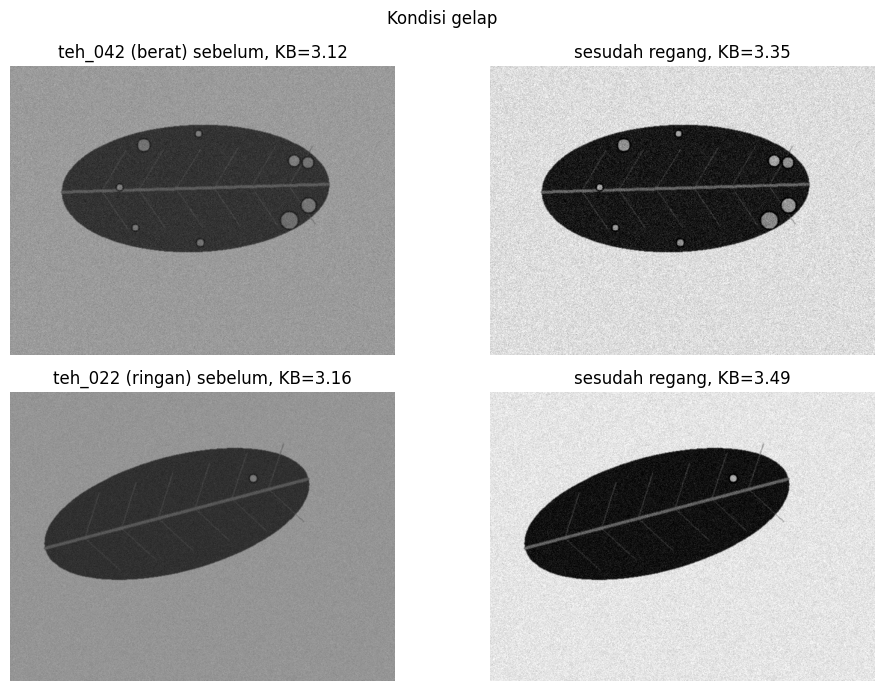

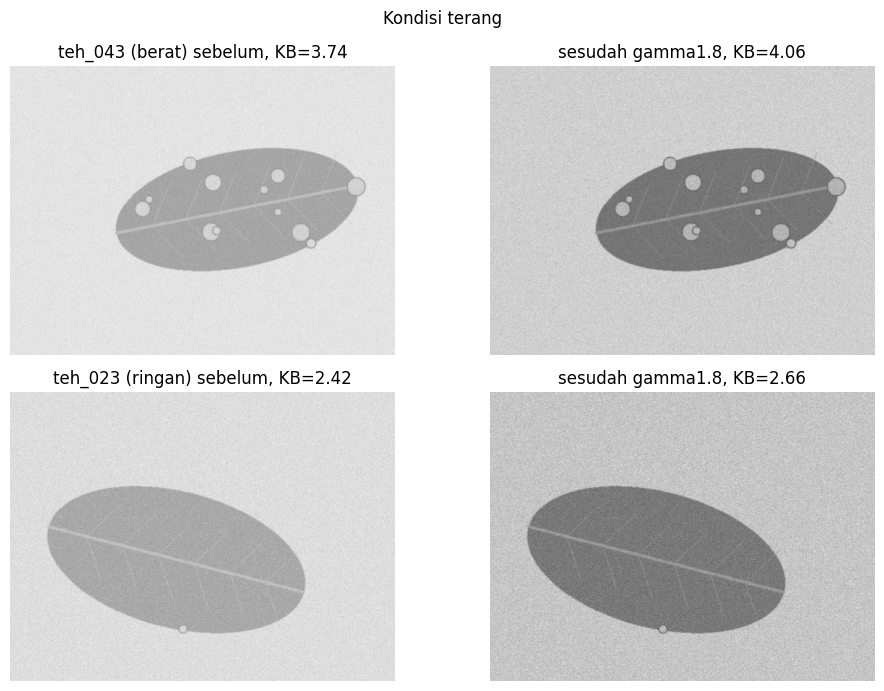

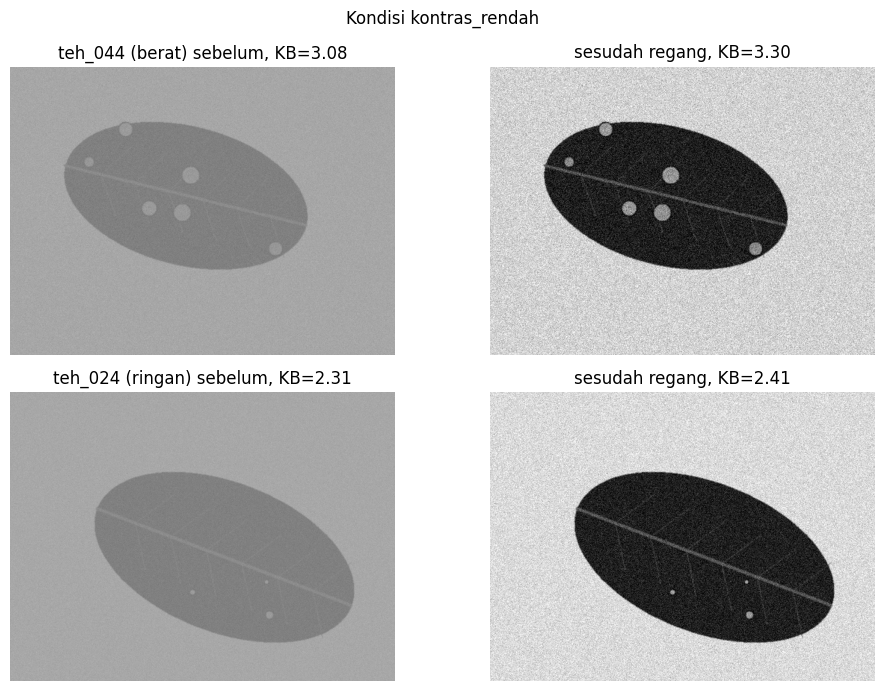

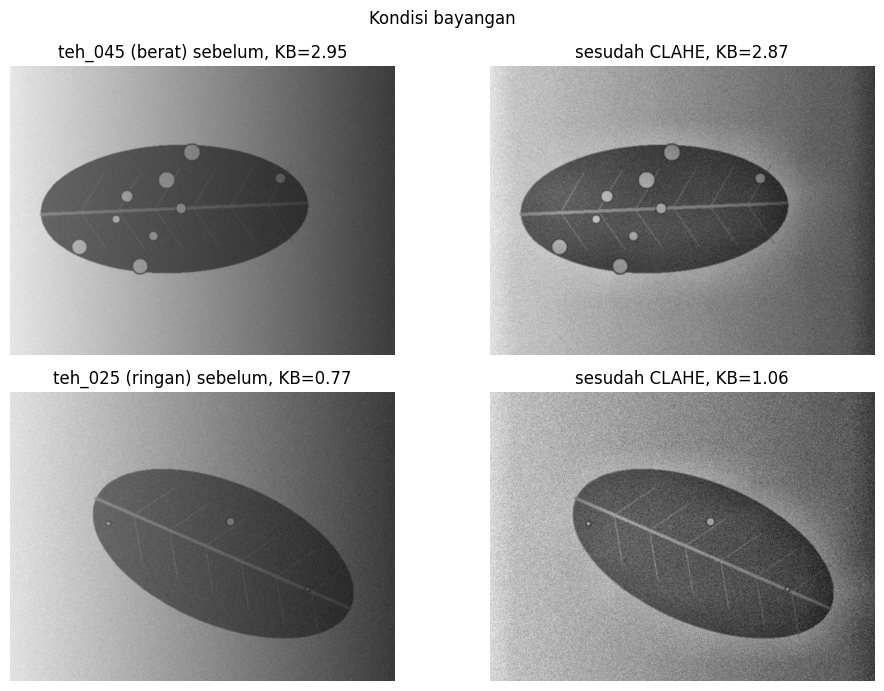

       kondisi   citra  kelas perbaikan  KB_sebelum  KB_sesudah  perubahan_%
         gelap teh_042  berat    regang        3.12        3.35          7.4
         gelap teh_022 ringan    regang        3.16        3.49         10.4
        terang teh_043  berat  gamma1.8        3.74        4.06          8.6
        terang teh_023 ringan  gamma1.8        2.42        2.66          9.9
kontras_rendah teh_044  berat    regang        3.08        3.30          7.1
kontras_rendah teh_024 ringan    regang        2.31        2.41          4.3
      bayangan teh_045  berat     CLAHE        2.95        2.87         -2.7
      bayangan teh_025 ringan     CLAHE        0.77        1.06         37.7


In [10]:
# Kode 3.5 Panel sebelum dan sesudah perbaikan terpilih (Langkah 3.5)
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

def regang(g):
    rmin, rmax = np.percentile(g, (2, 98))
    return np.clip((g.astype(float) - rmin) / (rmax - rmin) * 255,
                   0, 255).astype(np.uint8)

KANDIDAT = {
    "gamma0.5": lambda g: cv2.LUT(g, gamma_lut(0.5)),
    "gamma1.8": lambda g: cv2.LUT(g, gamma_lut(1.8)),
    "regang": regang,
    "ekualisasi": cv2.equalizeHist,
    "CLAHE": lambda g: cv2.createCLAHE(clipLimit=2.0,
                                       tileGridSize=(8, 8)).apply(g),
}

# pasangan (kelas berat, kelas ringan) untuk tiap kondisi
PASANGAN = {
    "gelap": ("teh_042.png", "teh_022.png"),
    "terang": ("teh_043.png", "teh_023.png"),
    "kontras_rendah": ("teh_044.png", "teh_024.png"),
    "bayangan": ("teh_045.png", "teh_025.png"),
}

# perbaikan terpilih per kondisi (berdasarkan tabel KB kandidat, Kode 3.4)
PILIHAN = {"gelap": "regang", "terang": "gamma1.8",
           "kontras_rendah": "regang", "bayangan": "CLAHE"}

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), md, mb

ringkas = []
for kd, (nb, nr) in PASANGAN.items():
    pilih = PILIHAN[kd]
    fig, ax = plt.subplots(2, 2, figsize=(10, 7))
    for r, (kelas, nama) in enumerate([("berat", nb), ("ringan", nr)]):
        g, md, mb = muat(nama)
        out = KANDIDAT[pilih](g)
        kb0 = kontras_bercak(g, md, mb)
        kb1 = kontras_bercak(out, md, mb)
        ringkas.append([kd, nama[:-4], kelas, pilih,
                        round(kb0, 2), round(kb1, 2)])
        ax[r, 0].imshow(g, cmap="gray", vmin=0, vmax=255)
        ax[r, 0].set_title(f"{nama[:-4]} ({kelas}) sebelum, KB={kb0:.2f}")
        ax[r, 1].imshow(out, cmap="gray", vmin=0, vmax=255)
        ax[r, 1].set_title(f"sesudah {pilih}, KB={kb1:.2f}")
        for a in ax[r]:
            a.axis("off")
    plt.suptitle(f"Kondisi {kd}")
    plt.tight_layout()
    plt.savefig(f"../hasil/b3_perbaikan_{kd}.png", dpi=150)
    plt.show()

tabel_pilihan = pd.DataFrame(ringkas, columns=["kondisi", "citra", "kelas",
                                               "perbaikan", "KB_sebelum",
                                               "KB_sesudah"])
tabel_pilihan["perubahan_%"] = ((tabel_pilihan.KB_sesudah / tabel_pilihan.KB_sebelum - 1)
                                * 100).round(1)
print(tabel_pilihan.to_string(index=False))
tabel_pilihan.to_csv("../hasil/b3_perbaikan_terpilih.csv", index=False)

In [8]:
!ls ../hasil

b1_bgr_rgb.png		     b3_histogram_ringan.png
b1_pipeline.png		     b3_kb_kandidat_per_kondisi.csv
b2_kanal_terbaik.png	     b3_panel_metode.png
b2_kb_kanal.csv		     b3_perbaikan_bayangan.png
b2_kb_kanal_ringan.csv	     b3_perbaikan_gelap.png
b2_panel_kanal.png	     b3_perbaikan_kontras_rendah.png
b2_sampling_kuantisasi.png   b3_perbaikan_terang.png
b3_clahe_parameter.csv	     b3_perbaikan_terpilih.csv
b3_clahe_warna.png	     b3_tabel10.csv
b3_gambar4_perbandingan.png  b3_tabel9.csv
b3_histogram_5kondisi.png    b3_tabel9_ringan_detail.csv


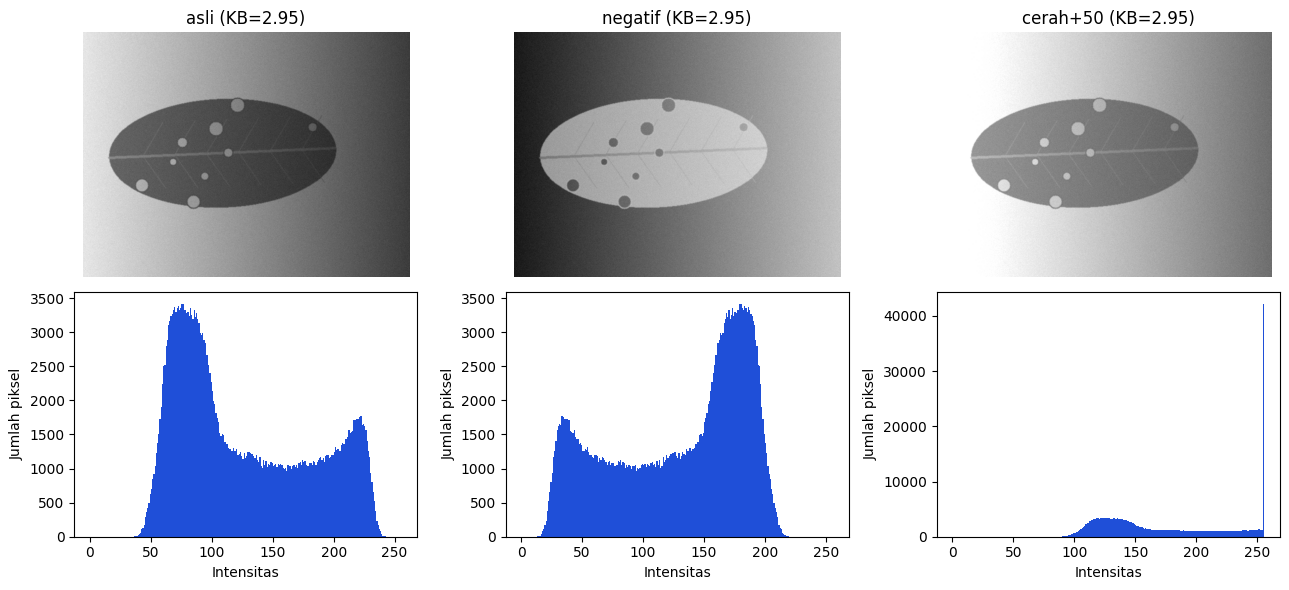

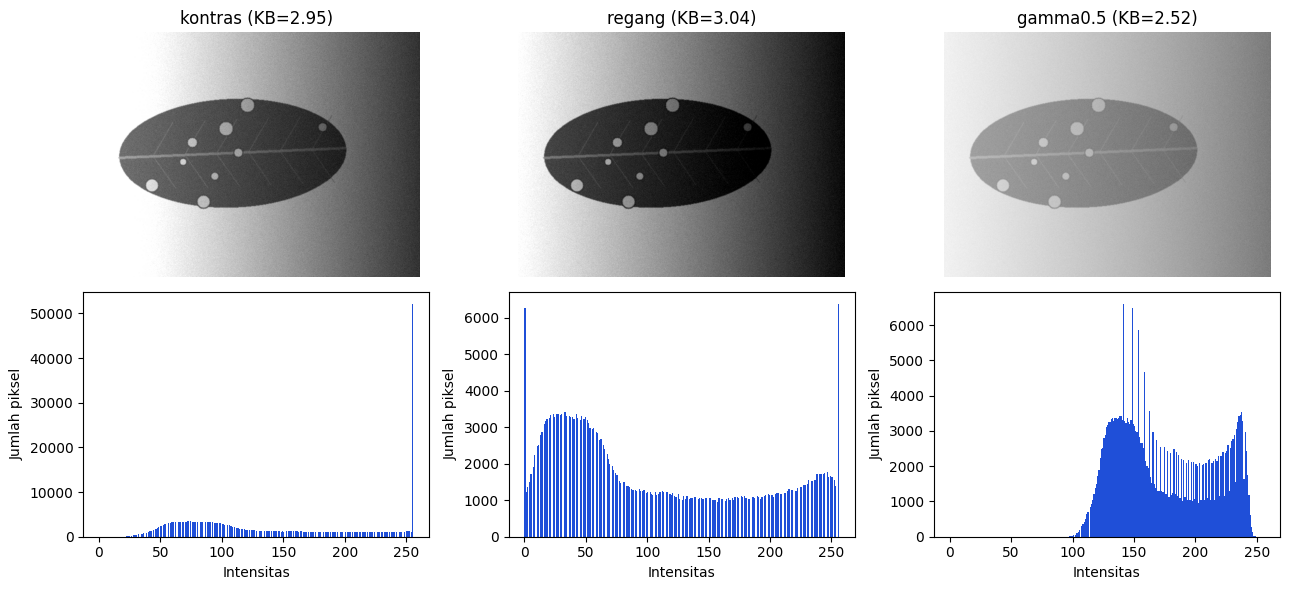

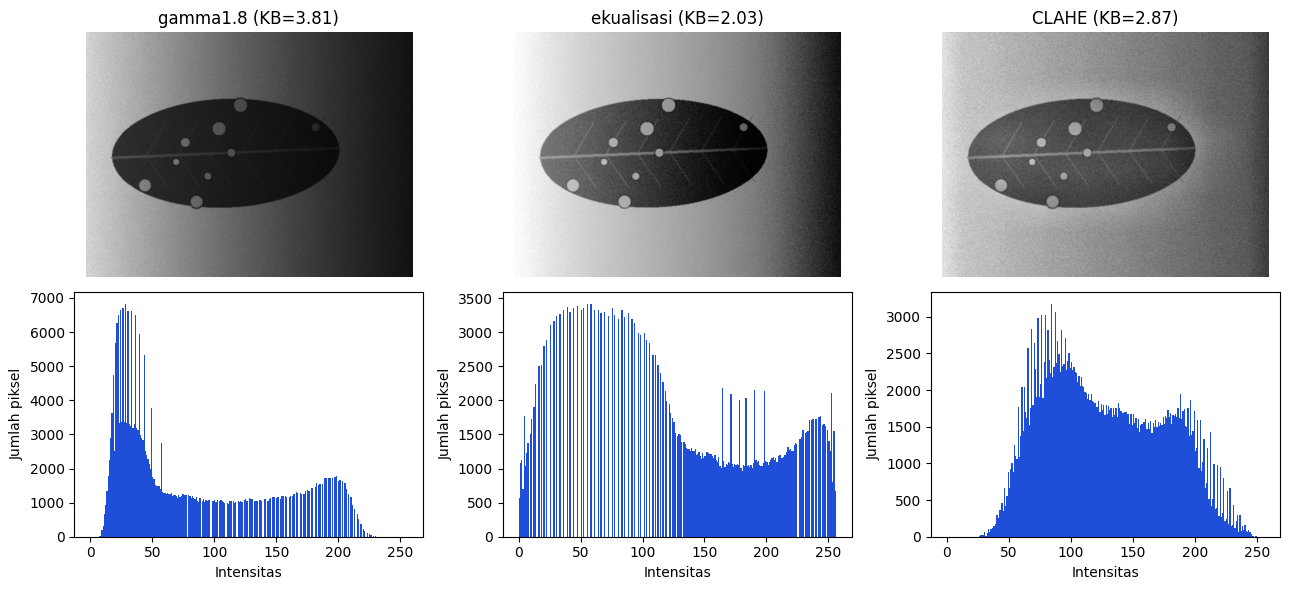

In [9]:
# Kode 3.2b Gambar 4 lengkap: setiap hasil bersama histogramnya
import sys
sys.path.append("../src")
import cv2, numpy as np, matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak

nama = "teh_045.png"  # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}

kelompok = [["asli", "negatif", "cerah+50"],
            ["kontras", "regang", "gamma0.5"],
            ["gamma1.8", "ekualisasi", "CLAHE"]]

for n, daftar in enumerate(kelompok, start=1):
    fig, ax = plt.subplots(2, 3, figsize=(13, 6))
    for i, k in enumerate(daftar):
        ax[0, i].imshow(hasil[k], cmap="gray", vmin=0, vmax=255)
        ax[0, i].set_title(f"{k} (KB={kontras_bercak(hasil[k], md, mb):.2f})")
        ax[0, i].axis("off")
        ax[1, i].hist(hasil[k].ravel(), bins=256, range=(0, 256),
                      color="#1f4fd8")
        ax[1, i].set_xlabel("Intensitas")
        ax[1, i].set_ylabel("Jumlah piksel")
    plt.tight_layout()
    plt.savefig(f"../hasil/b3_gambar4_bagian{n}.png", dpi=150)
    plt.show()

In [11]:
# Kode 3.6 Bukti P3.2: dI dan simpangan baku daun sehat (teh_045)
import sys
sys.path.append("../src")
import cv2, numpy as np
from utils_cv import baca

nama = "teh_045.png"
gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
sehat = (md > 0) & (mb == 0)
bercak = mb > 0

uji = {"asli": gray,
       "ekualisasi": cv2.equalizeHist(gray),
       "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)}
for nm, c in uji.items():
    k = c.astype(float)
    dI = abs(k[bercak].mean() - k[sehat].mean())
    sd = k[sehat].std()
    print(f"{nm:11s} dI={dI:.1f}  sigma_daun_sehat={sd:.1f}  KB={dI/sd:.2f}")

asli        dI=46.7  sigma_daun_sehat=15.8  KB=2.95
ekualisasi  dI=76.1  sigma_daun_sehat=37.5  KB=2.03
CLAHE       dI=53.9  sigma_daun_sehat=18.8  KB=2.87


In [12]:
# Unduh semua berkas hasil sekaligus
import shutil
from google.colab import files

shutil.make_archive("/content/hasil_semua", "zip",
                    "/content/simuteh-2330511010/hasil")
files.download("/content/hasil_semua.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>